[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_45N.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_30N.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_15N.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_0N.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_15S.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_30S.nc
[성공] 파일 로드 시작: ./PR_zscore_monthly_ensmean_45S.nc


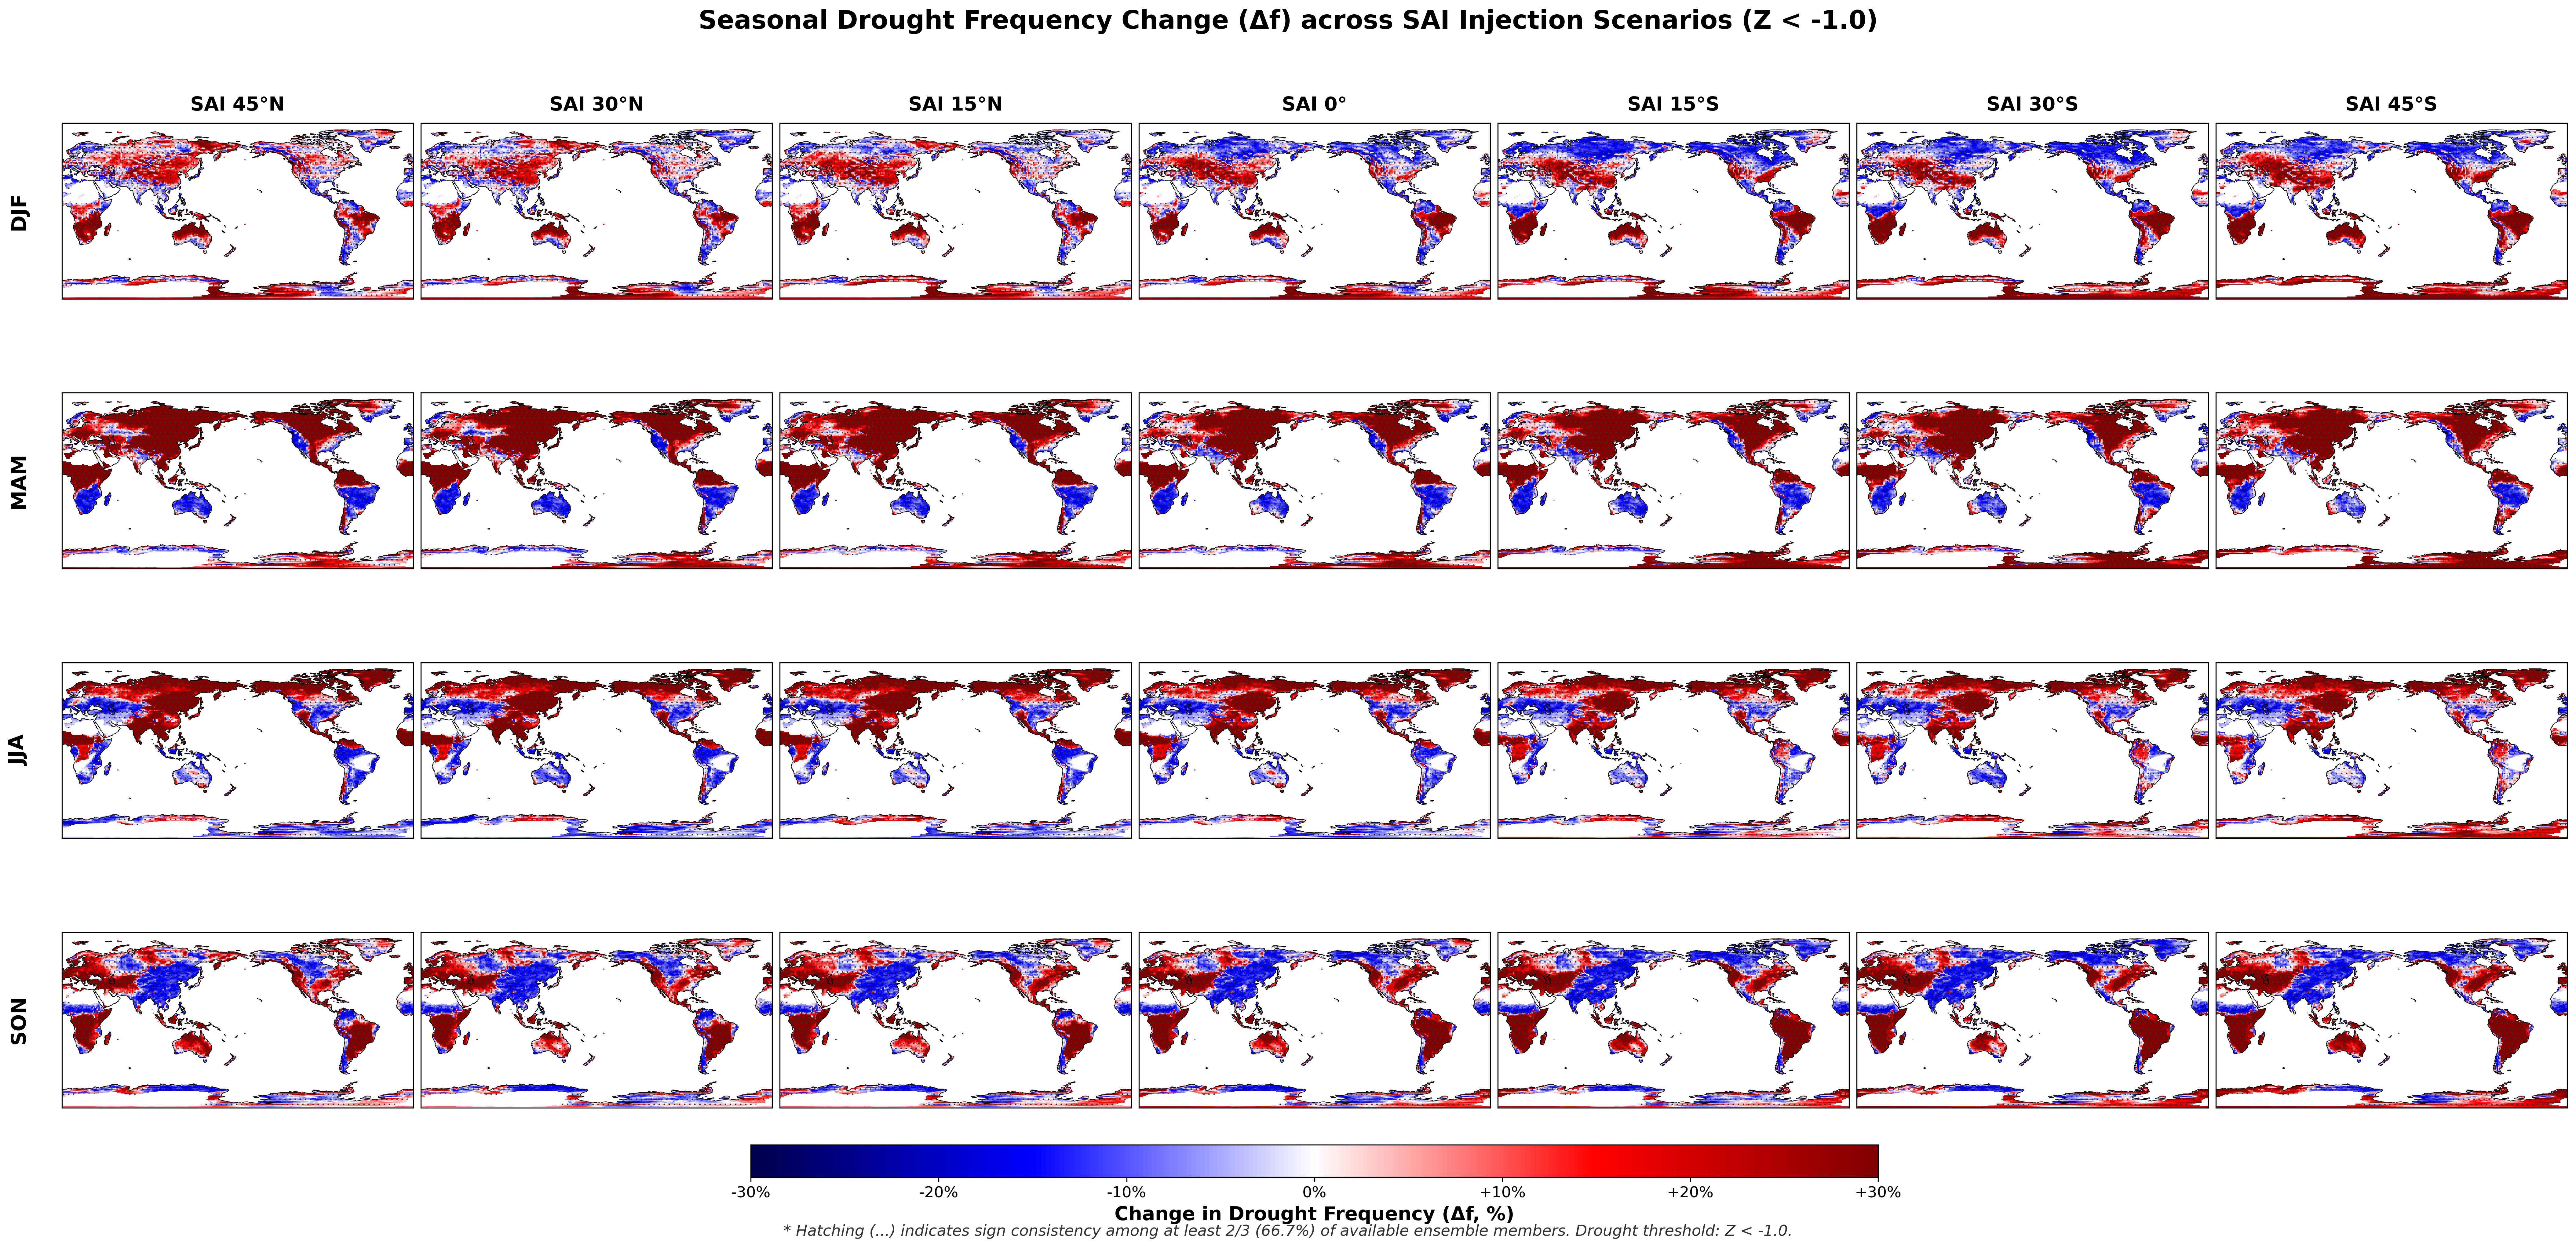

In [1]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from global_land_mask import globe

# 마스킹

DROUGHT_THRESHOLD = -1.0  # Z < -1.0
DATA_DIR = "./" 

ds_ssp_mean = xr.open_dataset(os.path.join(DATA_DIR, 'PR_mean.nc'), decode_times=False)

ssp_mean_grid = None
for var_name in ds_ssp_mean.data_vars:
    arr = ds_ssp_mean[var_name].squeeze()
    if arr.ndim == 2 and arr.shape == (192, 288):
        ssp_mean_grid = arr.values
        break

if ssp_mean_grid is None:
    var_key = 'pr' if 'pr' in ds_ssp_mean else ('PRECT' if 'PRECT' in ds_ssp_mean else list(ds_ssp_mean.data_vars)[0])
    ssp_mean_grid = ds_ssp_mean[var_key].squeeze().values

lats = np.clip(ds_ssp_mean['lat'].values, -90.0, 90.0)
lons = ds_ssp_mean['lon'].values
lons_180 = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

is_land = globe.is_land(lat_grid, lon_grid)
arid_threshold = 2.315e-6 if np.nanmean(ssp_mean_grid) > 1e-6 else 2.315e-9
valid_mask = is_land & (ssp_mean_grid >= arid_threshold)  # (192, 288)

ssp_z_file = os.path.join(DATA_DIR, 'PR_zscore_monthly_SSP.nc')
ds_ssp_z = xr.open_dataset(ssp_z_file, decode_times=False)

z_ssp = None
for var_name in ds_ssp_z.data_vars:
    arr = ds_ssp_z[var_name].values
    if arr.ndim == 3 and arr.shape == (360, 192, 288):
        z_ssp = arr
        break

seasons_idx = {
    'DJF': [i for i in range(360) if (i % 12) in [11, 0, 1]],
    'MAM': [i for i in range(360) if (i % 12) in [2, 3, 4]],
    'JJA': [i for i in range(360) if (i % 12) in [5, 6, 7]],
    'SON': [i for i in range(360) if (i % 12) in [8, 9, 10]]
}
seasons = ['DJF', 'MAM', 'JJA', 'SON']

f_ssp = np.zeros((4, 192, 288))
for s_idx, season in enumerate(seasons):
    t_indices = seasons_idx[season]
    drought_months = (z_ssp[t_indices, :, :] < DROUGHT_THRESHOLD).astype(float)
    f_ssp[s_idx] = np.nanmean(drought_months, axis=0)


lat_scenarios = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']
lat_titles = ['45°N', '30°N', '15°N', '0°', '15°S', '30°S', '45°S']
ensembles = ['e02', 'e03', 'e04', 'e05', 'e06', 'e07']

fig, axes = plt.subplots(
    nrows=4, ncols=7, figsize=(28, 13), dpi=300,
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)},
    constrained_layout=True
)

fig.suptitle(
    f'Seasonal Drought Frequency Change (Δf) across SAI Injection Scenarios (Z < {DROUGHT_THRESHOLD})',
    fontsize=20, fontweight='bold', y=1.02
)

im = None
plt.rcParams['hatch.linewidth'] = 0.4
plt.rcParams['hatch.color'] = '#333333'

for col_idx, lat_str in enumerate(lat_scenarios):
    ensmean_file = os.path.join(DATA_DIR, f"PR_zscore_monthly_ensmean_{lat_str}.nc")
    
    if not os.path.exists(ensmean_file):
        print(f"[경고] 파일을 찾을 수 없습니다: {ensmean_file}")
        continue
    else:
        print(f"[성공] 파일 로드 시작: {ensmean_file}")
        
    ds_ensmean = xr.open_dataset(ensmean_file)
    
    z_ensmean = None
    for var_name in ds_ensmean.data_vars:
        arr = ds_ensmean[var_name].values
        if arr.ndim == 3 and arr.shape == (360, 192, 288):
            z_ensmean = arr
            break
            
    f_sai_ensmean = np.zeros((4, 192, 288))
    for s_idx, season in enumerate(seasons):
        t_indices = seasons_idx[season]
        drought_months = (z_ensmean[t_indices, :, :] < DROUGHT_THRESHOLD).astype(float)
        f_sai_ensmean[s_idx] = np.nanmean(drought_months, axis=0)
        
    delta_f_ensmean = f_sai_ensmean - f_ssp

    member_delta_f_list = []
    for ens in ensembles:
        member_file = os.path.join(DATA_DIR, f"PR_zscore_monthly_{lat_str}_{ens}.nc")
        if os.path.exists(member_file):
            ds_m = xr.open_dataset(member_file)
            z_m = None
            for var_name in ds_m.data_vars:
                arr = ds_m[var_name].values
                if arr.ndim == 3 and arr.shape == (360, 192, 288):
                    z_m = arr
                    break
            if z_m is not None:
                f_m = np.zeros((4, 192, 288))
                for s_idx, season in enumerate(seasons):
                    t_indices = seasons_idx[season]
                    f_m[s_idx] = np.nanmean((z_m[t_indices, :, :] < DROUGHT_THRESHOLD).astype(float), axis=0)
                member_delta_f_list.append(f_m - f_ssp)
            
    member_stack = np.stack(member_delta_f_list, axis=0)
    n_valid_ens = len(member_delta_f_list)

    for row_idx, season in enumerate(seasons):
        ax = axes[row_idx, col_idx]
        
        season_mean = delta_f_ensmean[row_idx]
        season_stack = member_stack[:, row_idx, :, :]
        
        pos_count = np.sum(season_stack > 0, axis=0)
        neg_count = np.sum(season_stack < 0, axis=0)
        max_agree_ratio = np.maximum(pos_count, neg_count) / n_valid_ens
        hatch_mask = (max_agree_ratio >= (2/3)) & valid_mask
        
        season_mean_masked = np.where(valid_mask, season_mean, np.nan)
        season_mean_clipped = np.clip(season_mean_masked, -0.3, 0.3)
        
        im = ax.pcolormesh(
            lons, lats, season_mean_clipped,
            transform=ccrs.PlateCarree(),
            cmap='seismic', vmin=-0.3, vmax=0.3
        )
        
        ax.contourf(
            lons, lats, hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=['...'],
            colors='none',
            transform=ccrs.PlateCarree()
        )
        
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')
        
        if row_idx == 0:
            ax.set_title(f"SAI {lat_titles[col_idx]}", fontsize=15, fontweight='bold', pad=10)
        if col_idx == 0:
            ax.text(-0.15, 0.5, season, transform=ax.transAxes,
                    fontsize=16, fontweight='bold', va='center', rotation=90)

cbar = fig.colorbar(
    im, ax=axes, orientation='horizontal', 
    shrink=0.45, aspect=35, pad=0.03
)
cbar.set_label('Change in Drought Frequency (Δf, %)', fontsize=15, fontweight='bold')
cbar.ax.tick_params(labelsize=12)
cbar.set_ticks([-0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3])
cbar.set_ticklabels(['-30%', '-20%', '-10%', '0%', '+10%', '+20%', '+30%'])

fig.text(
    0.5, -0.01, 
    f'* Hatching (...) indicates sign consistency among at least 2/3 (66.7%) of available ensemble members. Drought threshold: Z < {DROUGHT_THRESHOLD}.',
    ha='center', fontsize=12, fontstyle='italic', color='#333333'
)

plt.savefig('Drought_Frequency_Change_4x7_map.png', dpi=300, bbox_inches='tight')
plt.show()